## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('yield_df.csv')
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [3]:
df.shape

(28242, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  str    
 2   Item                           28242 non-null  str    
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), str(2)
memory usage: 2.1 MB


In [5]:
df.describe(include="object")

,Area,Item
count,28242,28242
unique,101,10
top,India,Potatoes
freq,4048,4276


In [6]:
df.isnull().sum()

Unnamed: 0                       0
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
# Remove Unnecessary Column
df.drop(columns=["Unnamed: 0"], inplace=True)

In [9]:
# Rename Columns
df.rename(columns={
    "hg/ha_yield": "Yield",
    "average_rain_fall_mm_per_year": "Rainfall",
    "pesticides_tonnes": "Pesticides",
    "avg_temp": "Temperature"
}, inplace=True)

In [10]:
df.tail()

,Area,Item,Year,Yield,Rainfall,Pesticides,Temperature
28237,Zimbabwe,"Rice, paddy",2013,22581,657.0,2550.07,19.76
28238,Zimbabwe,Sorghum,2013,3066,657.0,2550.07,19.76
28239,Zimbabwe,Soybeans,2013,13142,657.0,2550.07,19.76
28240,Zimbabwe,Sweet potatoes,2013,22222,657.0,2550.07,19.76
28241,Zimbabwe,Wheat,2013,22888,657.0,2550.07,19.76


## EDA

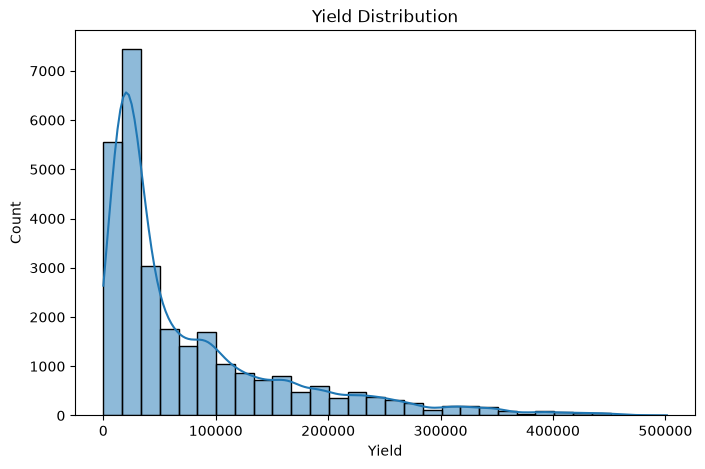

In [11]:
# Target Distribution
plt.figure(figsize=(8,5))
sns.histplot(
    df["Yield"],
    bins=30,
    kde=True
)
plt.title("Yield Distribution")
plt.show()

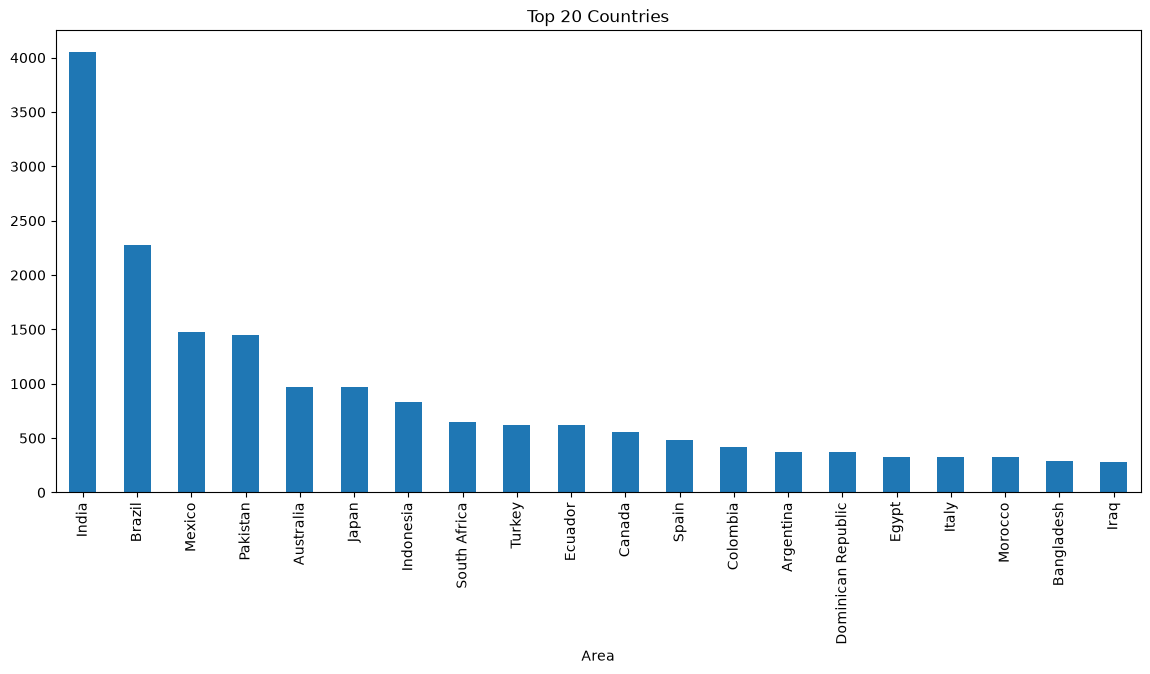

In [12]:
# Country Distribution
plt.figure(figsize=(14,6))
df["Area"].value_counts().head(20).plot(
    kind="bar"
)
plt.title("Top 20 Countries")
plt.show()

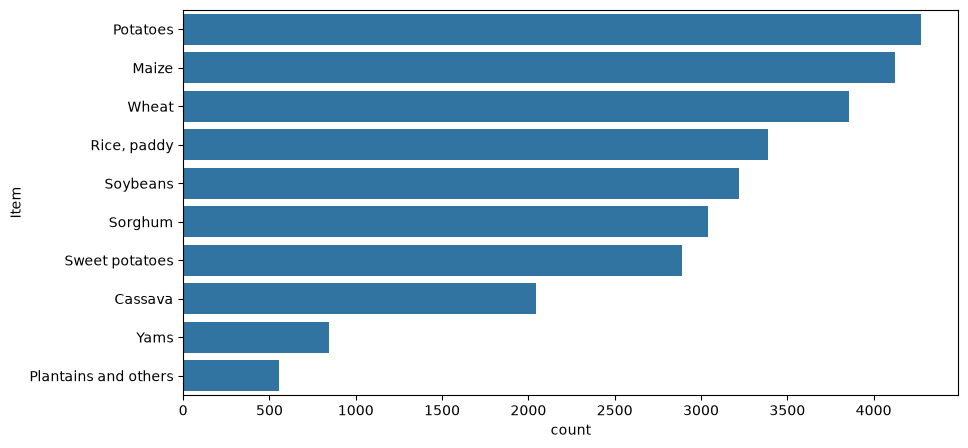

In [13]:
# Crop Distribution
plt.figure(figsize=(10,5))
sns.countplot(
    y="Item",
    data=df,
    order=df["Item"].value_counts().index
)
plt.show()

In [14]:
# Numerical Features
numerical_cols = [
    "Year",
    "Rainfall",
    "Pesticides",
    "Temperature",
    "Yield"
]

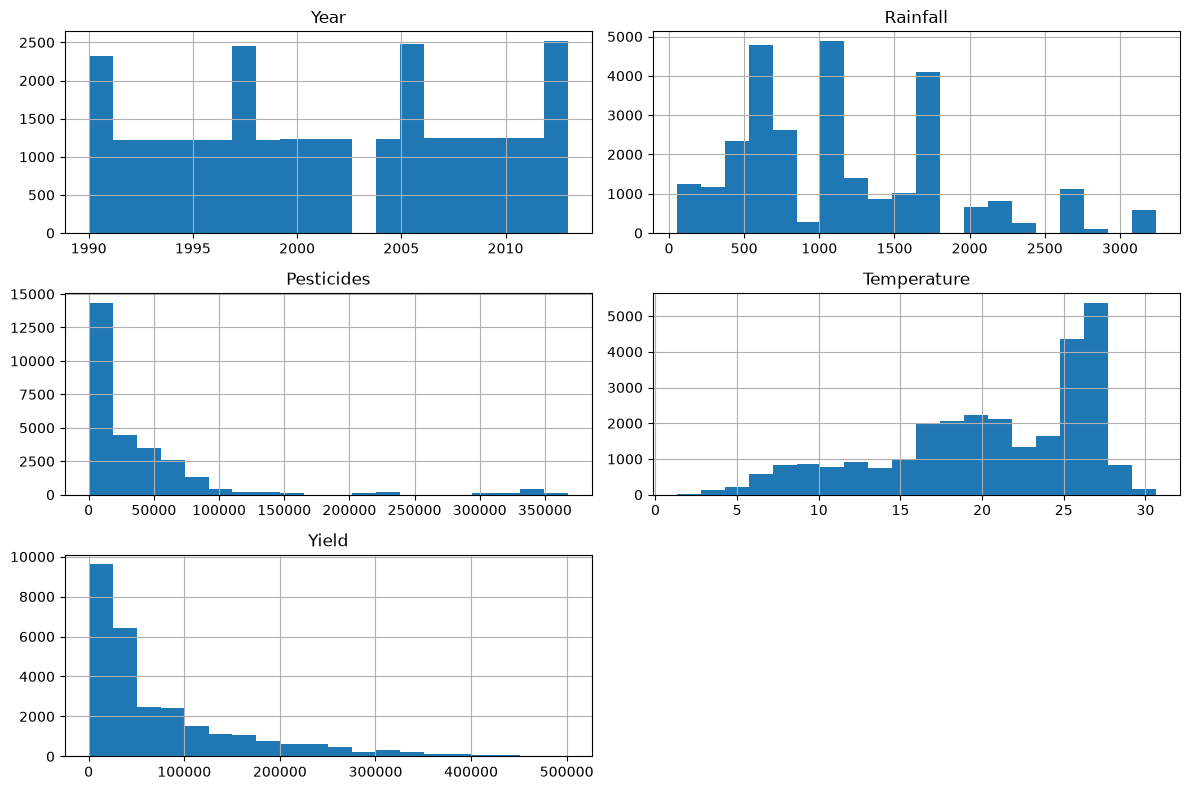

In [15]:
# Histograms
df[numerical_cols].hist(
    figsize=(12,8),
    bins=20
)
plt.tight_layout()
plt.show()

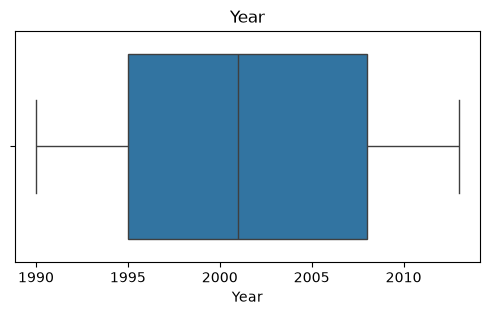

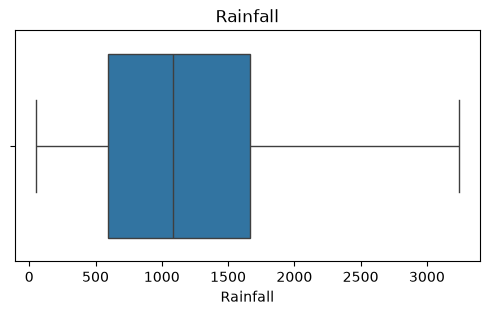

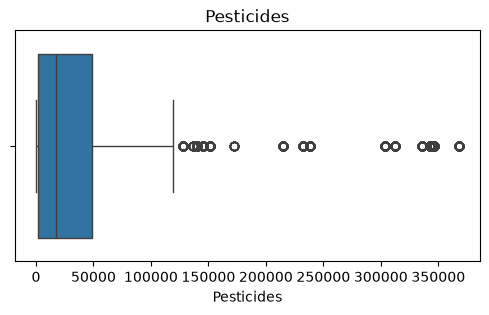

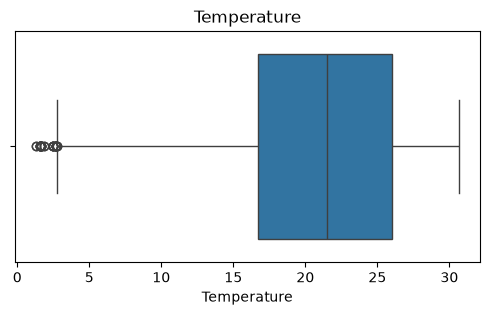

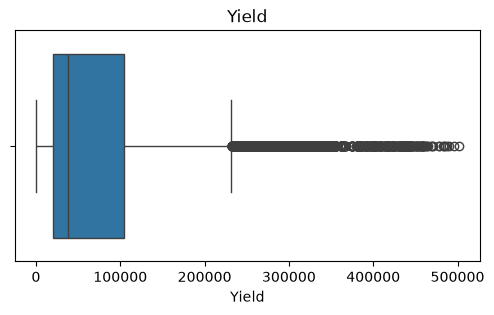

In [16]:
# Boxplots
for col in numerical_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(
        x=df[col]
    )
    plt.title(col)
    plt.show()

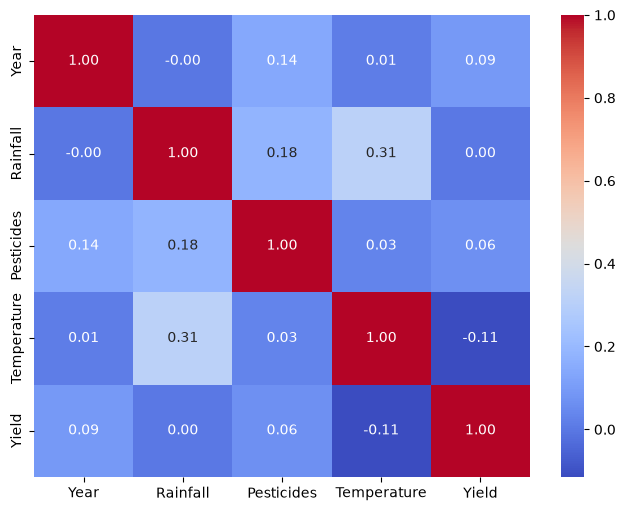

In [17]:
# Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(
    df[numerical_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()

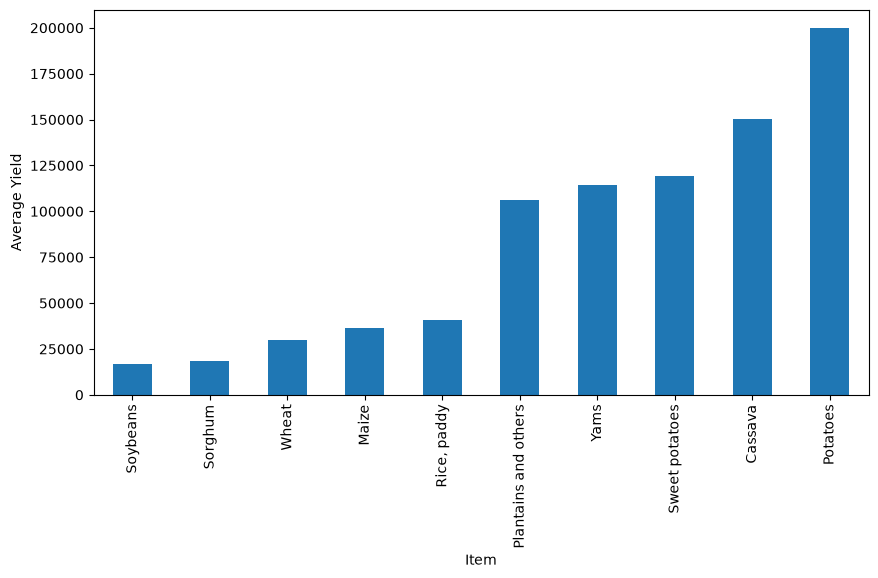

In [18]:
# Average Yield by Crop
plt.figure(figsize=(10,5))
df.groupby("Item")["Yield"].mean().sort_values().plot(kind="bar")
plt.ylabel("Average Yield")
plt.show()

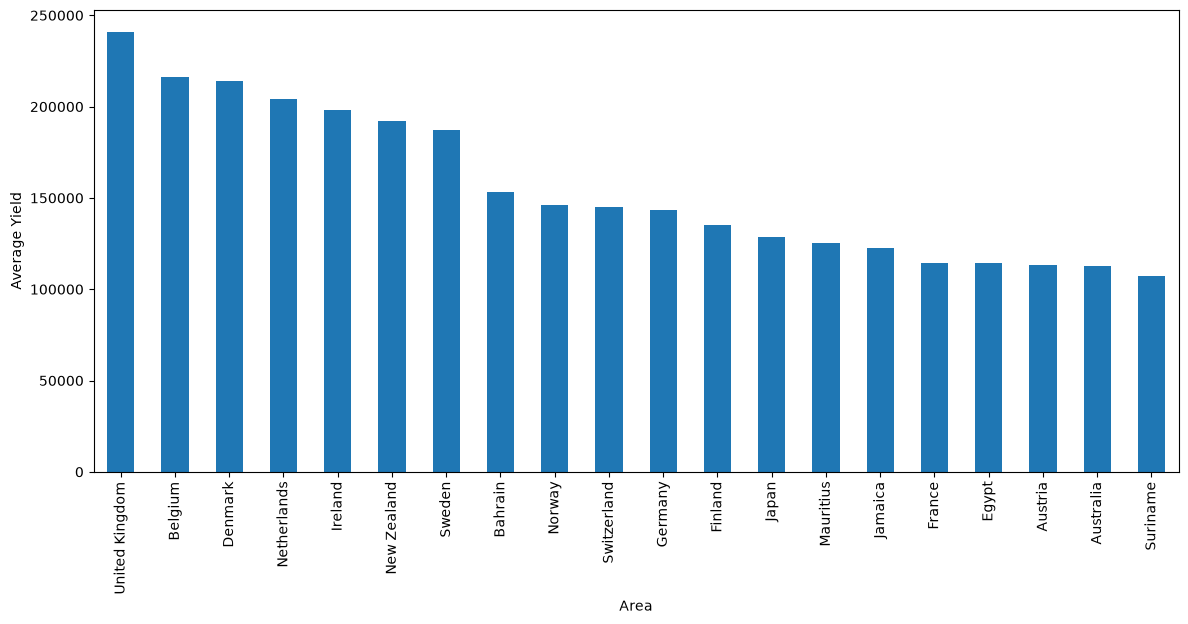

In [19]:
# Average Yield by Country
plt.figure(figsize=(14,6))
df.groupby("Area")["Yield"].mean().sort_values(ascending=False).head(20).plot(kind="bar")
plt.ylabel("Average Yield")
plt.show()

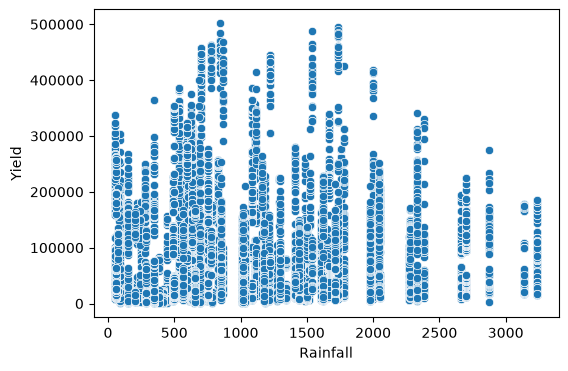

In [20]:
# Scatter Plots
plt.figure(figsize=(6,4))
sns.scatterplot(
    x="Rainfall",
    y="Yield",
    data=df
)
plt.show()

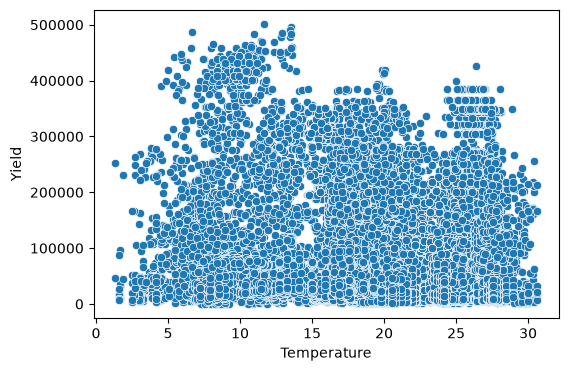

In [21]:
plt.figure(figsize=(6,4))
sns.scatterplot(
    x="Temperature",
    y="Yield",
    data=df
)
plt.show()

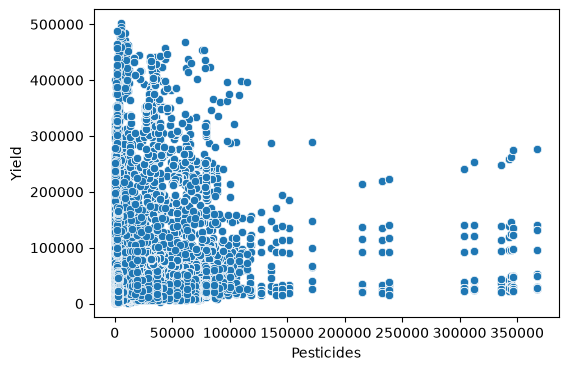

In [22]:
plt.figure(figsize=(6,4))
sns.scatterplot(
    x="Pesticides",
    y="Yield",
    data=df
)
plt.show()

## Features & Target

In [23]:
X = df.drop("Yield", axis=1)
y = df["Yield"]

In [24]:
# Train Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)

In [25]:
# Import Libraries
import time
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from xgboost import XGBRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.model_selection import (
    KFold,
    cross_val_score,
    GridSearchCV
)

In [26]:
# Define Features
categorical_features = [
    "Area",
    "Item"
]
numeric_features = [
    "Year",
    "Rainfall",
    "Pesticides",
    "Temperature"
]

In [27]:
# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]
)

In [28]:
# Pipelines
models = {

    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(random_state=42))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            random_state=42,
            objective="reg:squarederror"
        ))
    ])

}

In [29]:
# Evaluation Function
def evaluate_models(models, X_train, X_test, y_train, y_test):
    results = []
    trained_models = {}
    for name, model in models.items():
        train_start = time.time()
        model.fit(X_train, y_train)
        train_time = time.time() - train_start
        pred_start = time.time()
        y_pred = model.predict(X_test)
        pred_time = time.time() - pred_start
        r2 = r2_score(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        trained_models[name] = model
        results.append({
            "Model": name,
            "R2 Score": r2,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "Train Time (s)": train_time,
            "Prediction Time (s)": pred_time
        })
    results = pd.DataFrame(results)
    results = results.sort_values(
        by=["R2 Score", "RMSE"],
        ascending=[False, True]
    )
    return results, trained_models

In [30]:
# Train all Models
results, trained_models = evaluate_models(
    models,
    X_train,
    X_test,
    y_train,
    y_test
)
results

,Model,R2 Score,MAE,MSE,RMSE,Train Time (s),Prediction Time (s)
2,Random Forest,0.987643,3466.645442,8.963372e+07,9467.508855,182.643784,0.392356
1,Decision Tree,0.978827,3696.846344,1.535832e+08,12392.868569,2.522490,0.024632
4,XGBoost,0.975921,7721.621582,1.746623e+08,13215.986077,0.506176,0.053753
3,Gradient Boosting,0.873241,19396.278598,9.194661e+08,30322.698696,6.199491,0.045324
0,Linear Regression,0.644824,31791.648282,2.576333e+09,50757.595121,0.123670,0.021966


In [31]:
# Cross Validation Function
def cross_validation(models, X, y):
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    scores = []
    for name, model in models.items():
        r2 = cross_val_score(
            model,
            X,
            y,
            cv=cv,
            scoring="r2",
            n_jobs=-1
        )
        scores.append({
            "Model": name,
            "Mean R2": r2.mean(),
            "Std": r2.std()
        })

    return pd.DataFrame(scores).sort_values(
        by="Mean R2",
        ascending=False
    )

In [32]:
cv_results = cross_validation(models, X, y)
cv_results

,Model,Mean R2,Std
2,Random Forest,0.988120,0.000505
1,Decision Tree,0.980272,0.001328
4,XGBoost,0.975216,0.002048
3,Gradient Boosting,0.871619,0.007070
0,Linear Regression,0.635076,0.008511


In [33]:
best_pipeline = trained_models["Random Forest"]
joblib.dump(best_pipeline, "yield_pipeline.pkl")

['yield_pipeline.pkl']

In [34]:
# Test Prediction
pipeline = joblib.load("yield_pipeline.pkl")

sample = pd.DataFrame({
    "Area": ["India"],
    "Item": ["Rice, paddy"],
    "Year": [2025],
    "Rainfall": [1200],
    "Pesticides": [150],
    "Temperature": [27]
})

prediction = pipeline.predict(sample)
print(f"Predicted Yield: {prediction[0]:.2f} hg/ha")

Predicted Yield: 24993.16 hg/ha
